In [1]:
%pip install pandas numpy scikit-learn seaborn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
import os

train_path = "train_dataset.csv" if os.path.exists("train_dataset.csv") else r"C:\Users\ice55\Downloads\Aihack Thailand 2026\train_dataset.csv"
test_path = "test_without_gt.csv" if os.path.exists("test_without_gt.csv") else r"C:\Users\ice55\Downloads\Aihack Thailand 2026\test_without_gt.csv"
submission_path = "submission_template_for_test.csv" if os.path.exists("submission_template_for_test.csv") else r"C:\Users\ice55\Downloads\Aihack Thailand 2026\submission_template_for_test.csv"

train_data = pd.read_csv(train_path)
test_data = pd.read_csv(test_path)
submission_data = pd.read_csv(submission_path)

In [3]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

In [5]:
train_data

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211880002,0,18,1,2,699,141,140,8,6,...,300000,1,50000,1,2,1,1,1,1,1
1,211870004,0,20,2,2,419,26,640,1,1,...,200000,3,0,0,1,0,0,1,0,0
2,211930001,0,1,2,1,322,181,540,8,5,...,100000,1,0,3,0,0,0,1,1,1
3,211920001,0,17,1,1,328,328,640,1,5,...,100000,1,0,3,0,0,1,1,1,1
4,211880003,1,18,1,1,451,44,1040,16,1,...,100000,4,60000,0,0,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,215470332,0,17,1,2,372,372,640,99,5,...,200000,1,0,2,1,0,0,1,1,1
68542,215470333,0,18,2,1,362,18,640,99,5,...,50000,5,53000,0,1,1,0,1,1,0
68543,215480285,0,18,1,2,457,44,340,4,1,...,300000,1,0,2,2,1,0,1,1,1
68544,215470336,0,20,1,1,293,293,640,9,4,...,50000,2,0,3,0,0,1,1,0,0


In [6]:
test_data

,ID,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,Insurance Type,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211850001,20,1,1,301,301,640,1,1,1,...,200000,1,0,1,0,0,1,1,1,0
1,211850002,20,1,2,274,15,640,5,1,1,...,200000,1,40000,1,1,1,0,1,1,0
2,211850003,20,1,2,771,28,640,99,4,1,...,500000,4,50000,0,0,0,0,1,1,1
3,211870001,17,1,2,370,26,640,5,1,1,...,200000,4,54000,0,1,1,0,1,1,1
4,211880001,17,2,1,270,1,540,1,5,1,...,150000,4,48000,0,0,0,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137086,215490262,20,1,1,268,3,540,99,1,1,...,200000,4,1000,0,0,0,0,1,1,0
137087,215490263,17,1,2,604,187,740,9,1,1,...,50000,1,90000,1,4,2,1,1,1,1
137088,215490264,20,1,1,496,70,440,8,1,1,...,200000,1,0,3,0,0,1,1,1,0
137089,215490265,18,1,1,409,409,240,1,1,1,...,200000,1,0,3,0,0,1,1,1,1


In [7]:
submission_data

,ID,12-Month Default Flag
0,211850001,0
1,211850002,0
2,211850003,0
3,211870001,0
4,211880001,0
...,...,...
137086,215490262,0
137087,215490263,0
137088,215490264,0
137089,215490265,0


##

## Data preprocessing

In [8]:
Factors_train_data = train_data.copy()

In [9]:
Factors_train_data

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211880002,0,18,1,2,699,141,140,8,6,...,300000,1,50000,1,2,1,1,1,1,1
1,211870004,0,20,2,2,419,26,640,1,1,...,200000,3,0,0,1,0,0,1,0,0
2,211930001,0,1,2,1,322,181,540,8,5,...,100000,1,0,3,0,0,0,1,1,1
3,211920001,0,17,1,1,328,328,640,1,5,...,100000,1,0,3,0,0,1,1,1,1
4,211880003,1,18,1,1,451,44,1040,16,1,...,100000,4,60000,0,0,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,215470332,0,17,1,2,372,372,640,99,5,...,200000,1,0,2,1,0,0,1,1,1
68542,215470333,0,18,2,1,362,18,640,99,5,...,50000,5,53000,0,1,1,0,1,1,0
68543,215480285,0,18,1,2,457,44,340,4,1,...,300000,1,0,2,2,1,0,1,1,1
68544,215470336,0,20,1,1,293,293,640,9,4,...,50000,2,0,3,0,0,1,1,0,0


#### Checking missing value data

In [10]:
Factors_train_data.isna().sum()

ID                                 0
12-Month Default Flag              0
Application Channel                0
Gender                             0
Marital Status                     0
Age (in months)                    0
Residence Period (in months)       0
Occupation Category                0
Industry Category                  0
Employment Type Category           0
Insurance Type                     0
Company Size Category              0
Business Entity Type               0
Declared Annual Income             0
Payday                             0
Declared Number of Borrowings      0
Declared Borrowing Amount          0
Desired Credit Limit               0
Residence Type                     0
Rent Burden                        0
Residence Ownership Status         0
Number of Dependents               0
Number of Dependent Children       0
Home Phone Number Available        0
Mobile Phone Number Available      0
Employer Phone Number Available    0
Driver Licence Number Available    0
d

##

##

##

## Data Analysis

In [11]:
# Dataset overview
print("Shape:", Factors_train_data.shape)

# Data types
Factors_train_data.info()

# Statistical summary
display(Factors_train_data.describe().T)

# First 5 rows
display(Factors_train_data.head())

Shape: (68546, 27)
<class 'pandas.DataFrame'>
RangeIndex: 68546 entries, 0 to 68545
Data columns (total 27 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   ID                               68546 non-null  int64
 1   12-Month Default Flag            68546 non-null  int64
 2   Application Channel              68546 non-null  int64
 3   Gender                           68546 non-null  int64
 4   Marital Status                   68546 non-null  int64
 5   Age (in months)                  68546 non-null  int64
 6   Residence Period (in months)     68546 non-null  int64
 7   Occupation Category              68546 non-null  int64
 8   Industry Category                68546 non-null  int64
 9   Employment Type Category         68546 non-null  int64
 10  Insurance Type                   68546 non-null  int64
 11  Company Size Category            68546 non-null  int64
 12  Business Entity Type             68546

,count,mean,std,min,25%,50%,75%,max
ID,68546.0,2.136238e+08,1.017470e+06,211850010.0,2.127305e+08,213570122.5,214510033.5,2.154903e+08
12-Month Default Flag,68546.0,9.676713e-02,2.956426e-01,0.0,0.000000e+00,0.0,0.0,1.000000e+00
Application Channel,68546.0,1.697823e+01,4.630383e+00,1.0,1.700000e+01,18.0,20.0,2.000000e+01
Gender,68546.0,1.312316e+00,4.634412e-01,1.0,1.000000e+00,1.0,2.0,2.000000e+00
Marital Status,68546.0,1.311324e+00,4.630382e-01,1.0,1.000000e+00,1.0,2.0,2.000000e+00
Age (in months),68546.0,4.153405e+02,1.530383e+02,234.0,2.820000e+02,368.0,530.0,8.400000e+02
Residence Period (in months),68546.0,1.301110e+02,1.355671e+02,0.0,2.300000e+01,77.0,214.0,8.380000e+02
Occupation Category,68546.0,6.315283e+02,3.241452e+02,140.0,5.400000e+02,640.0,640.0,1.540000e+03
Industry Category,68546.0,3.433815e+01,4.184968e+01,1.0,5.000000e+00,9.0,99.0,9.900000e+01
Employment Type Category,68546.0,2.539754e+00,2.014826e+00,1.0,1.000000e+00,1.0,5.0,8.000000e+00


,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211880002,0,18,1,2,699,141,140,8,6,...,300000,1,50000,1,2,1,1,1,1,1
1,211870004,0,20,2,2,419,26,640,1,1,...,200000,3,0,0,1,0,0,1,0,0
2,211930001,0,1,2,1,322,181,540,8,5,...,100000,1,0,3,0,0,0,1,1,1
3,211920001,0,17,1,1,328,328,640,1,5,...,100000,1,0,3,0,0,1,1,1,1
4,211880003,1,18,1,1,451,44,1040,16,1,...,100000,4,60000,0,0,0,0,1,1,1


#### Outlier

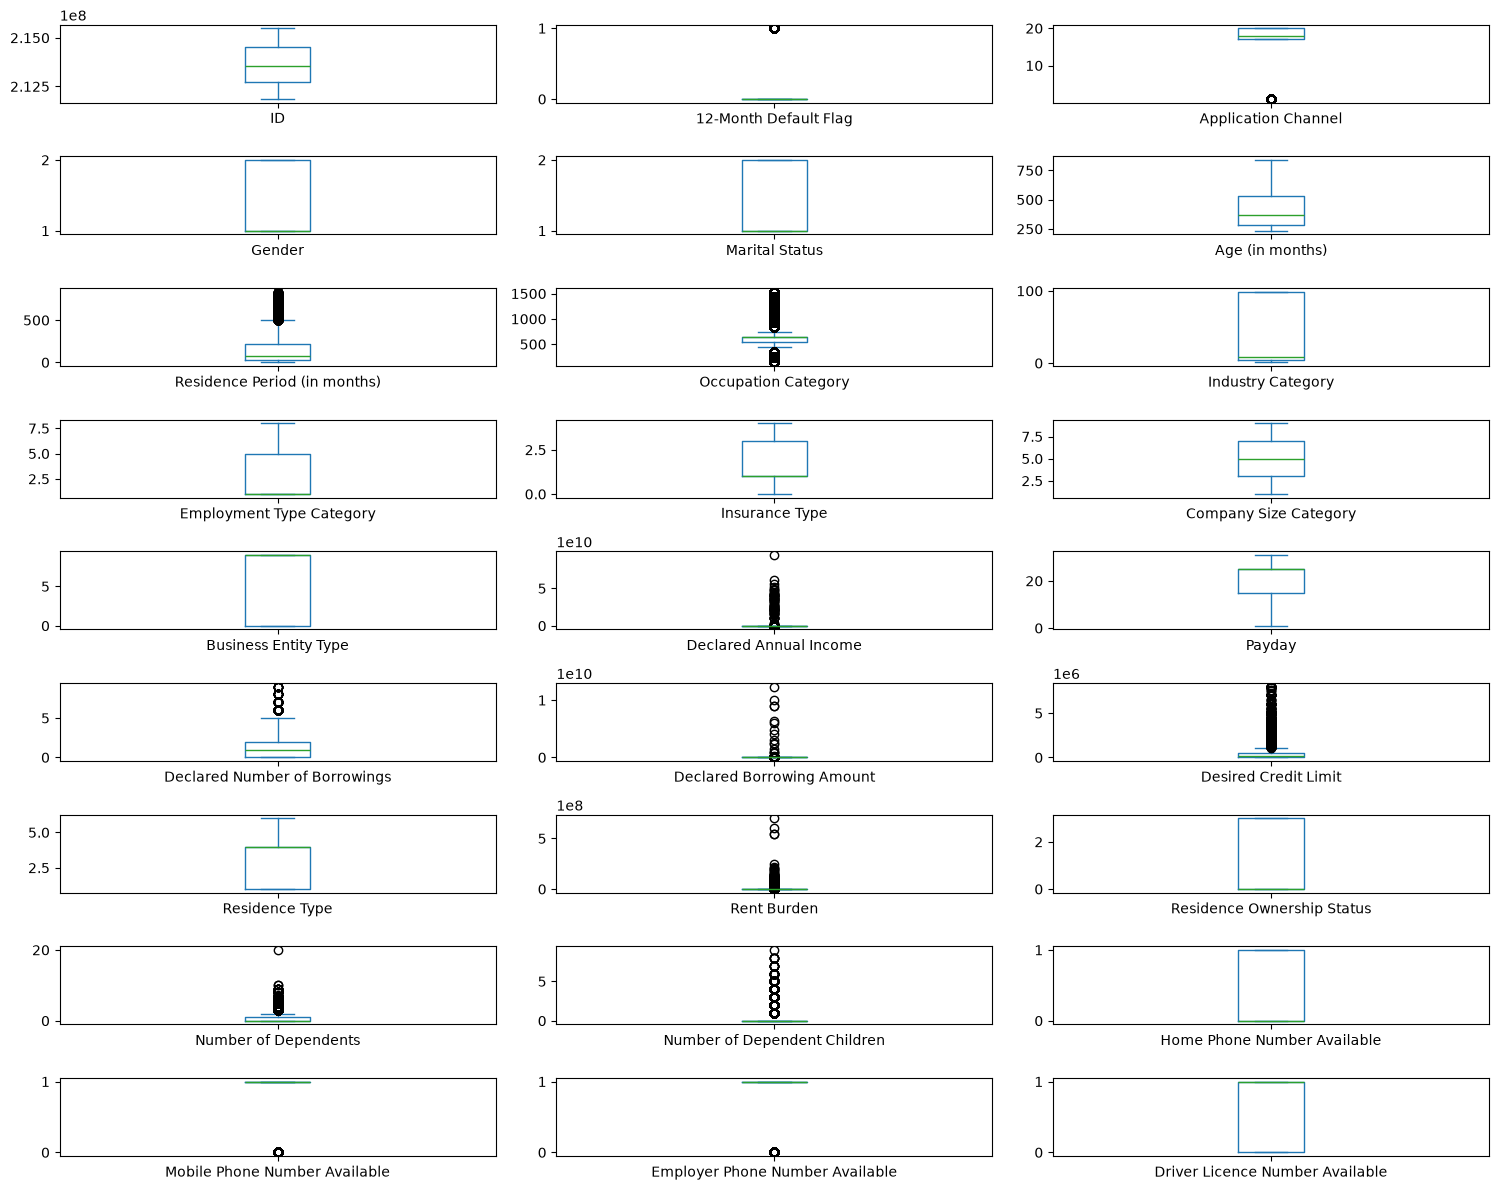

In [12]:
Factors_train_data.select_dtypes(include='number').plot(
    kind='box',
    subplots=True,
    layout=(-1, 3),
    figsize=(15, 12),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

#### Class Imbalance


In [13]:
target = '12-Month Default Flag'

# Count
print(Factors_train_data[target].value_counts())

# Percentage
print(Factors_train_data[target].value_counts(normalize=True) * 100)

12-Month Default Flag
0    61913
1     6633
Name: count, dtype: int64
12-Month Default Flag
0    90.323287
1     9.676713
Name: proportion, dtype: float64


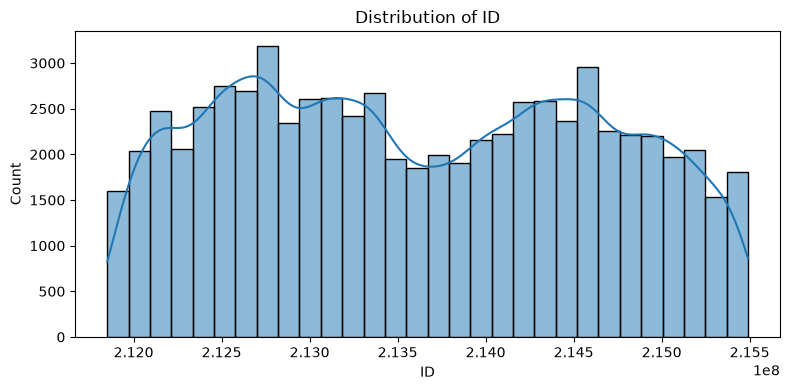

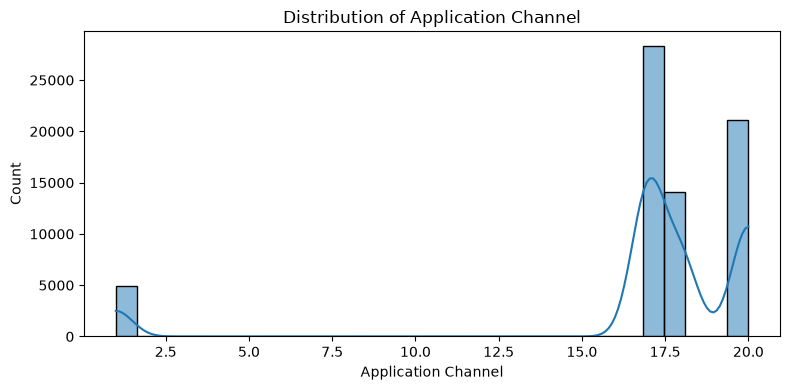

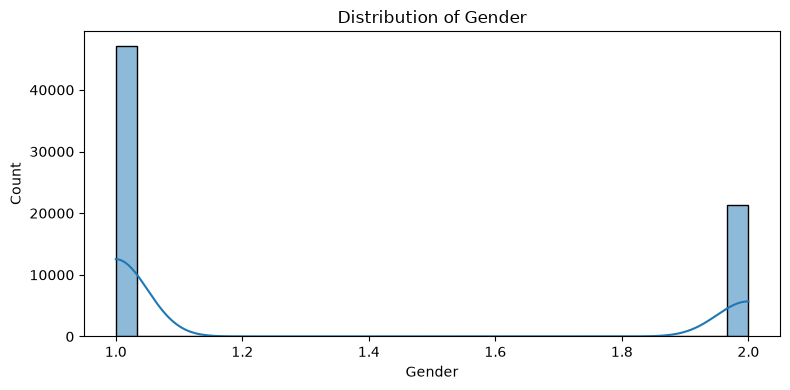

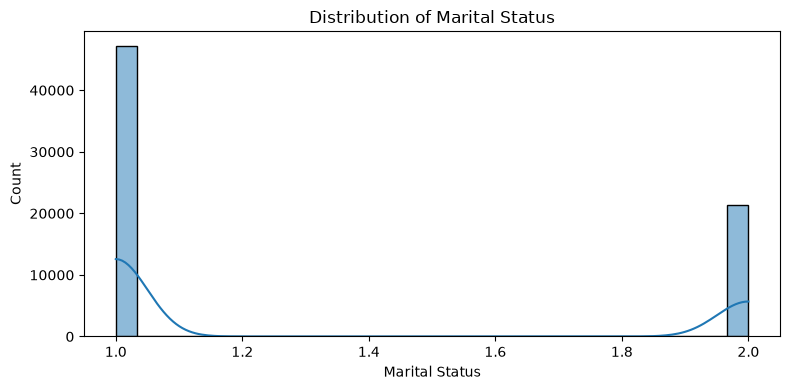

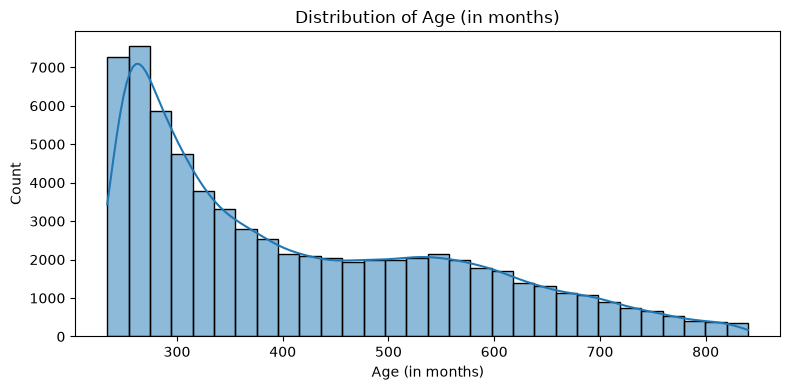

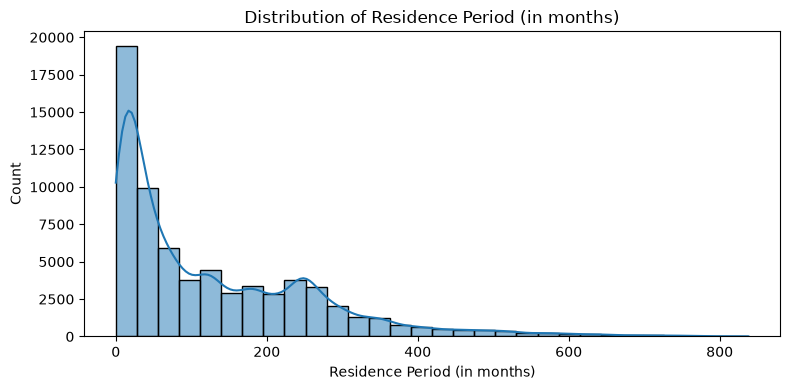

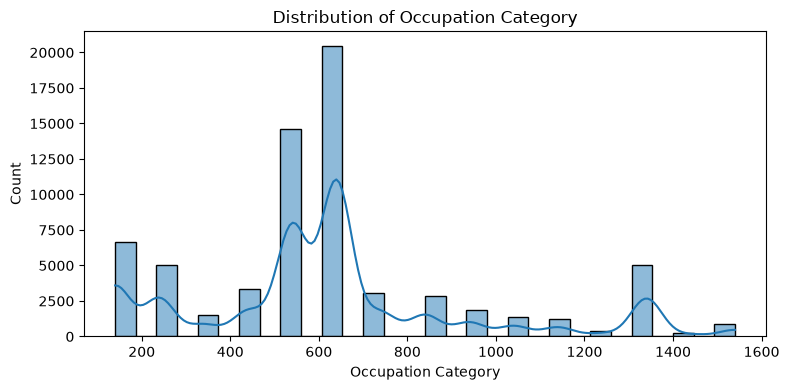

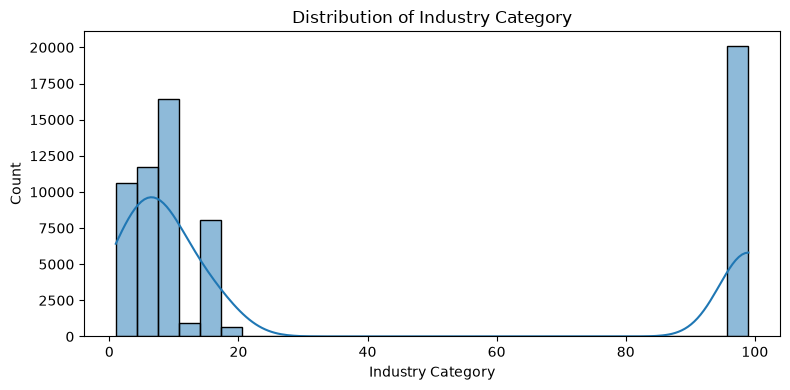

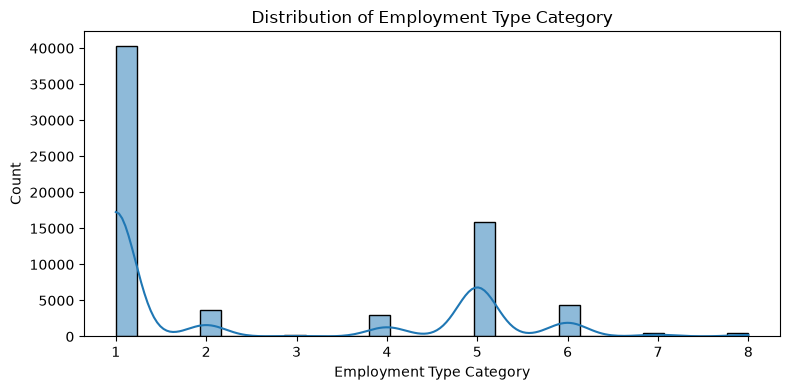

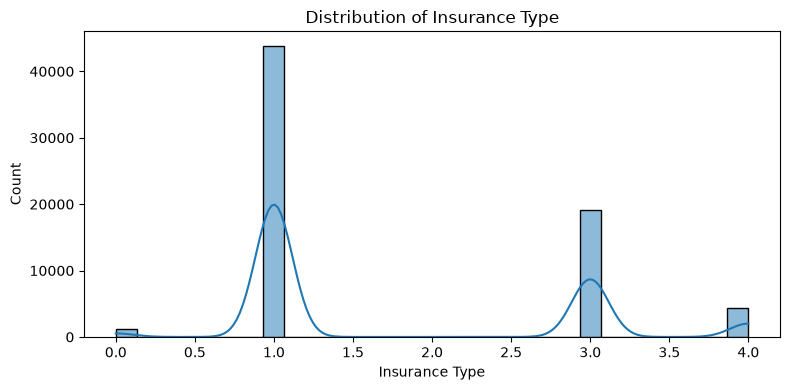

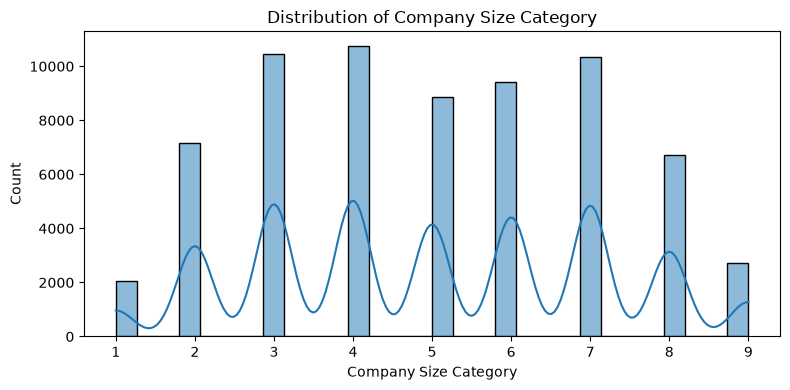

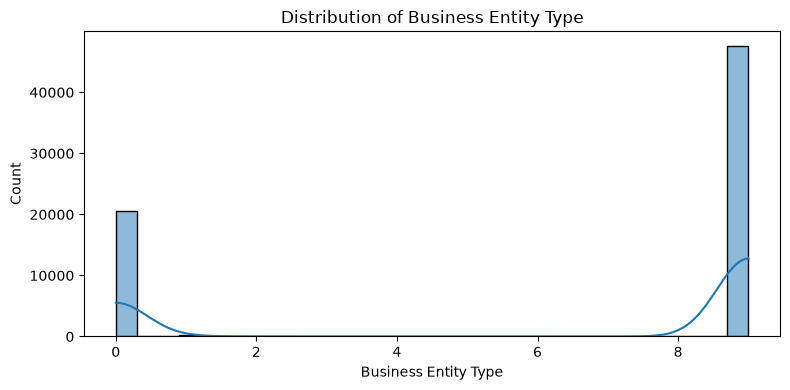

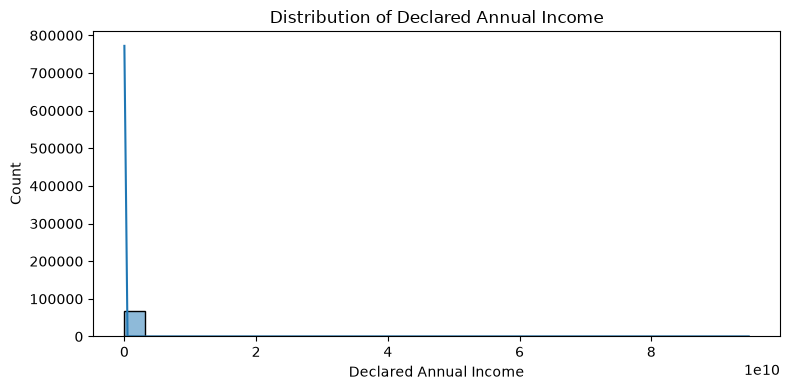

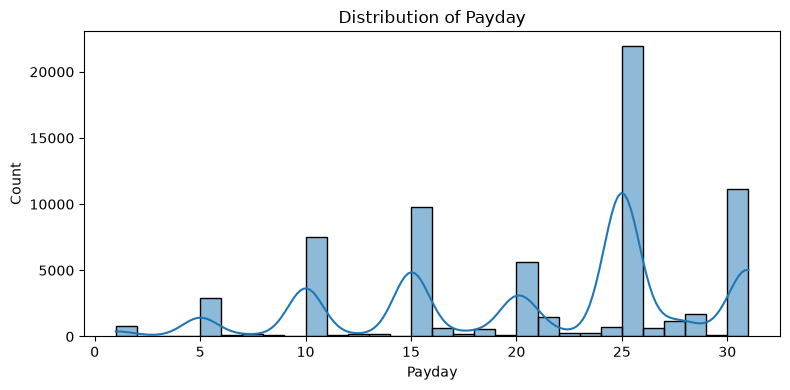

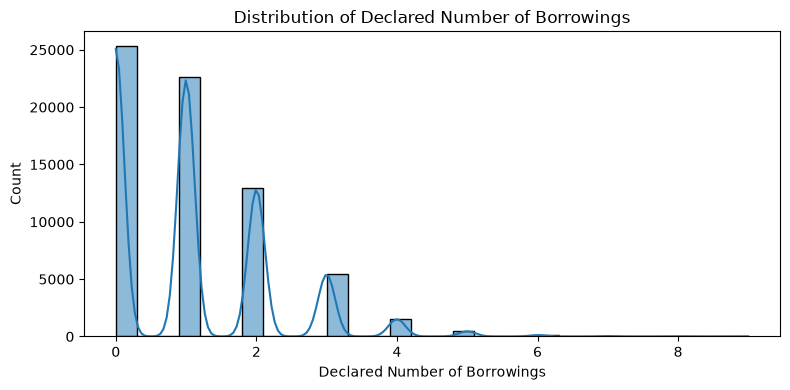

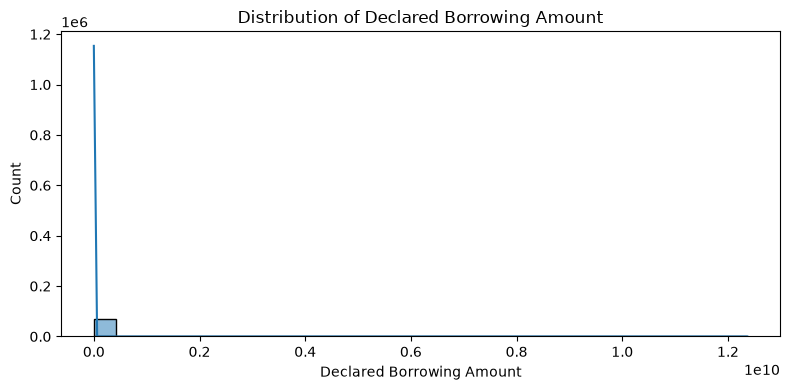

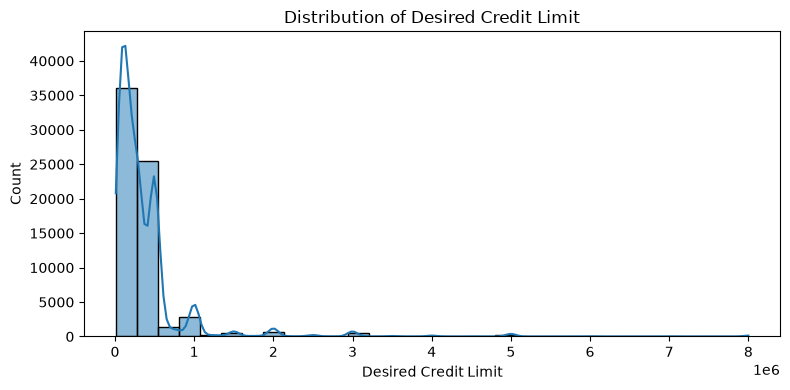

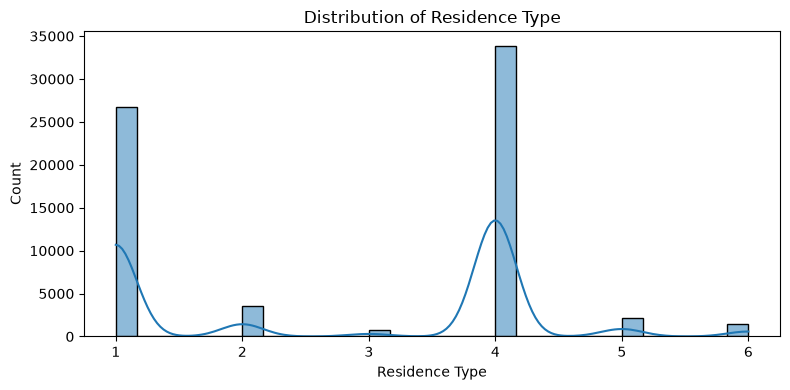

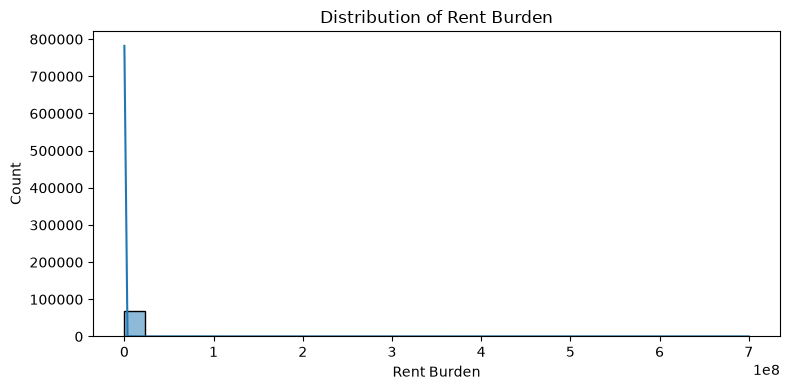

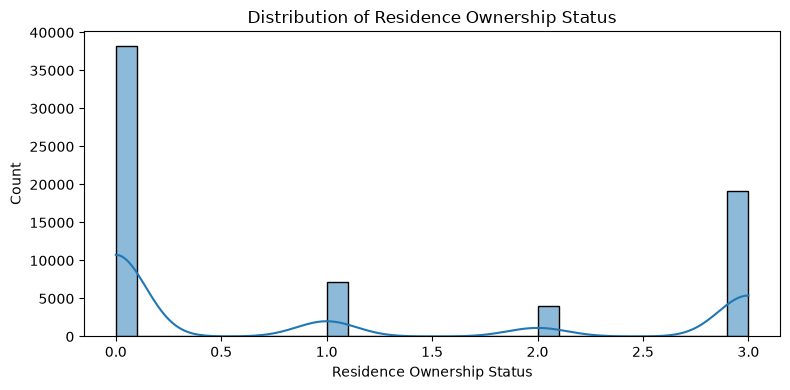

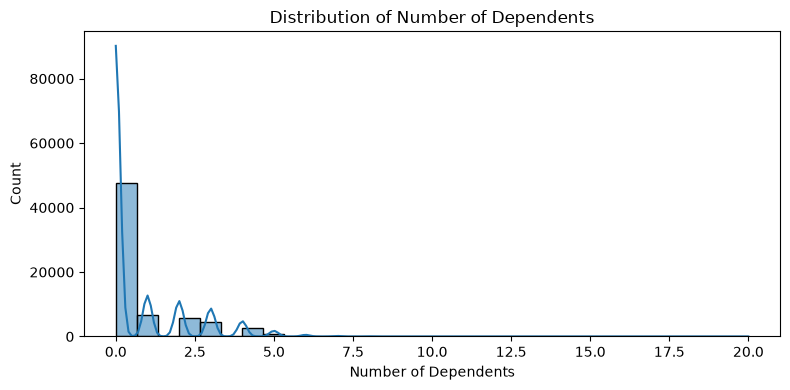

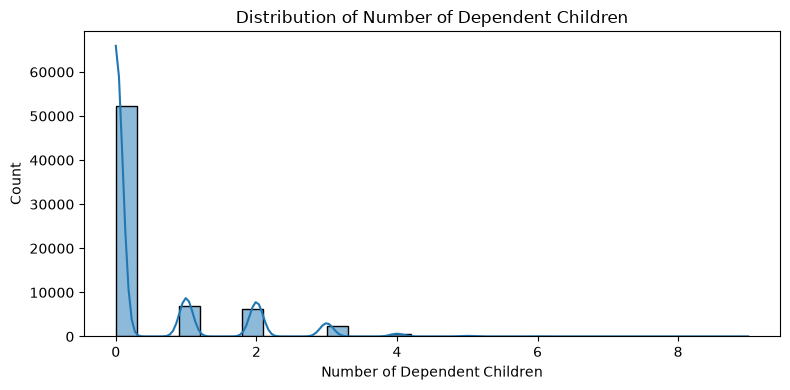

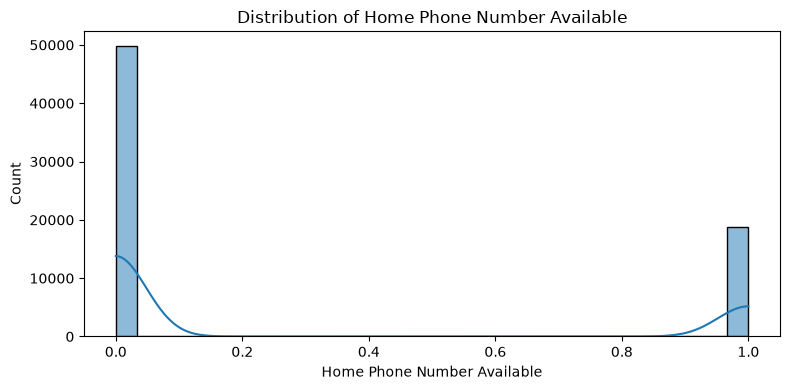

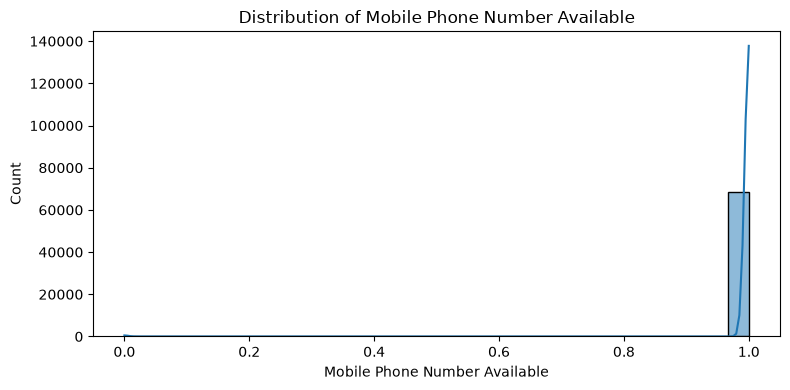

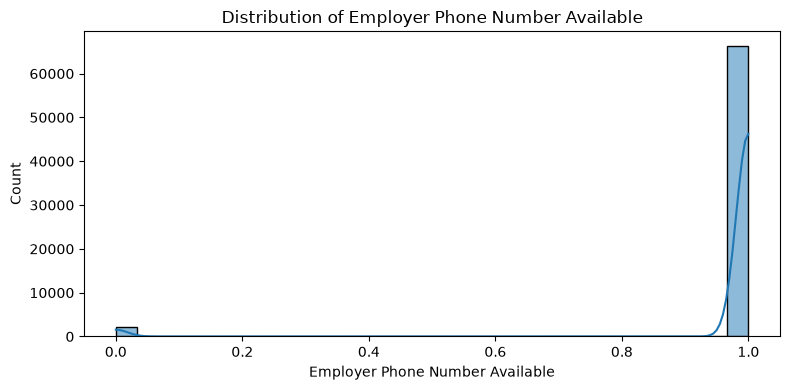

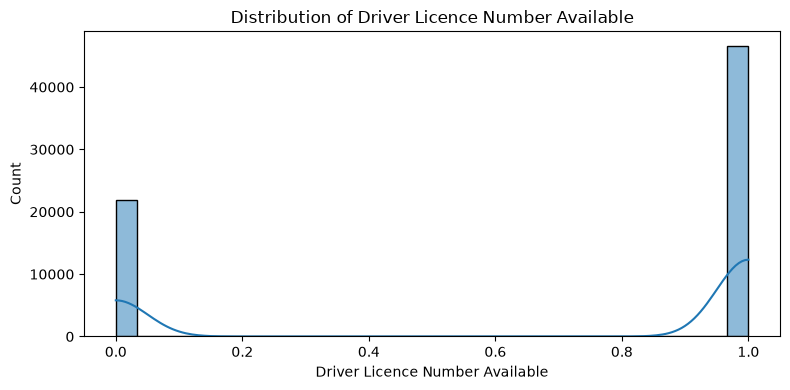

In [14]:
numeric_cols = Factors_train_data.select_dtypes(
    include='number'
).columns.drop(target, errors='ignore')

for col in numeric_cols:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=Factors_train_data,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

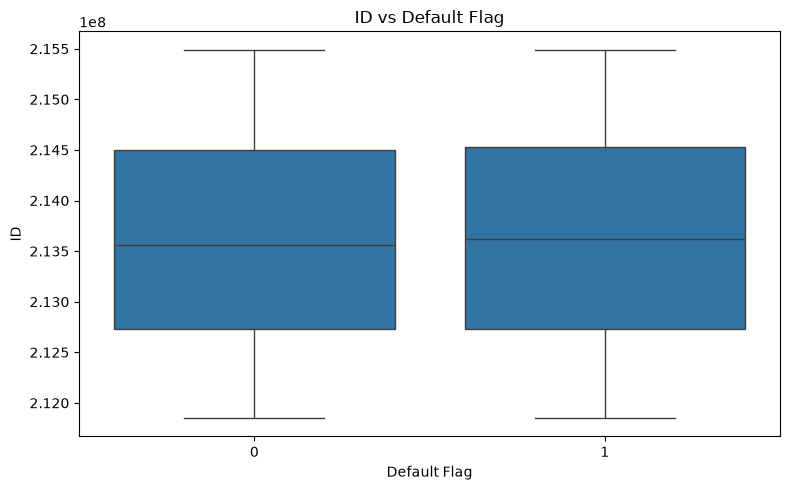

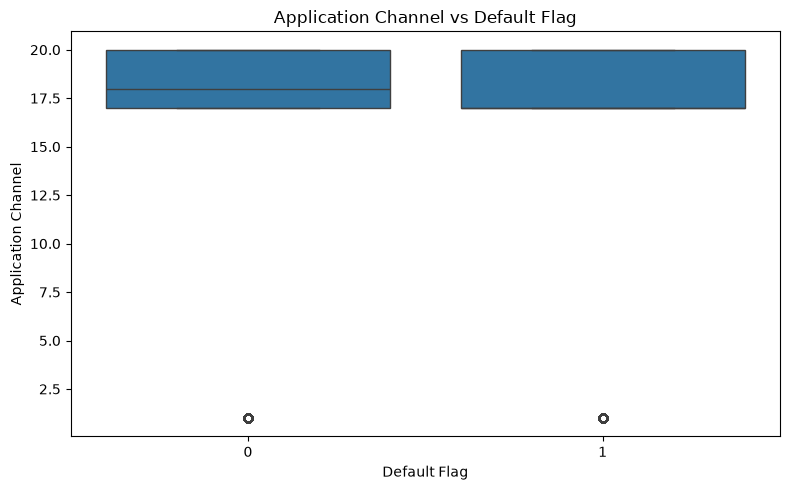

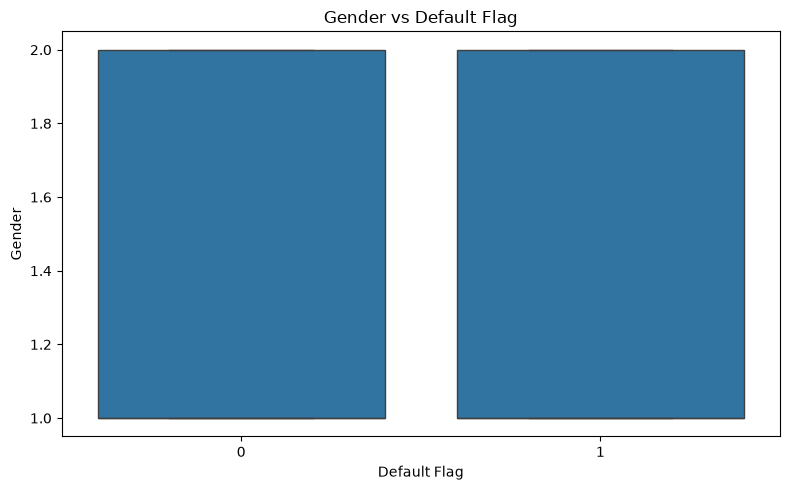

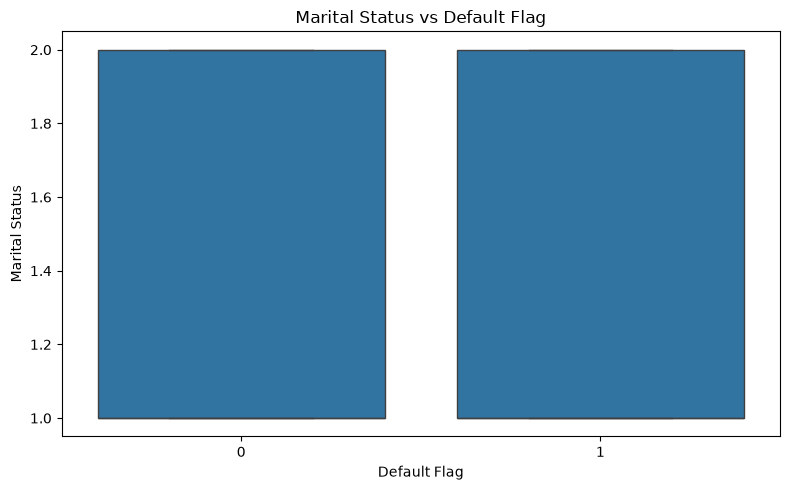

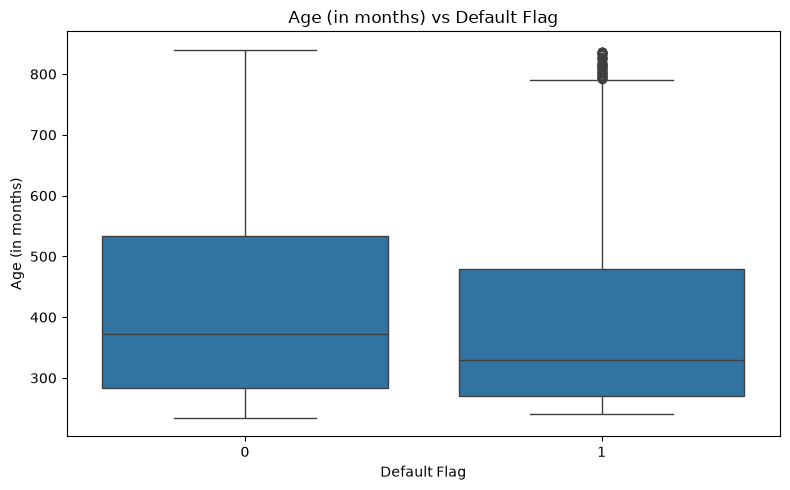

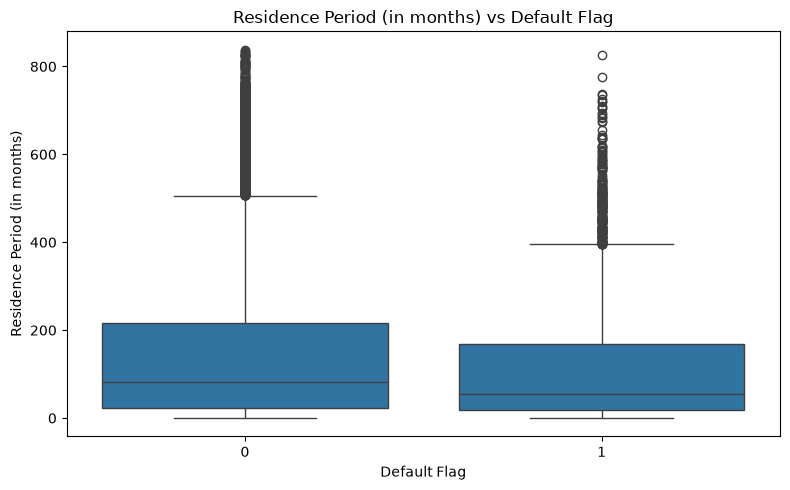

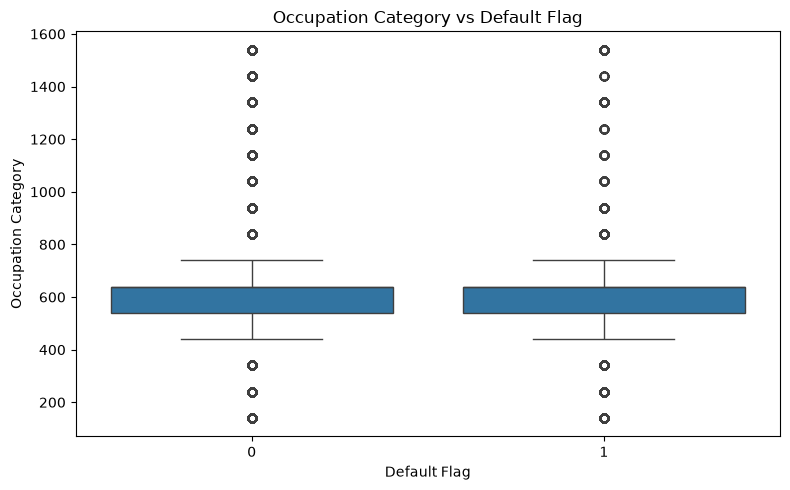

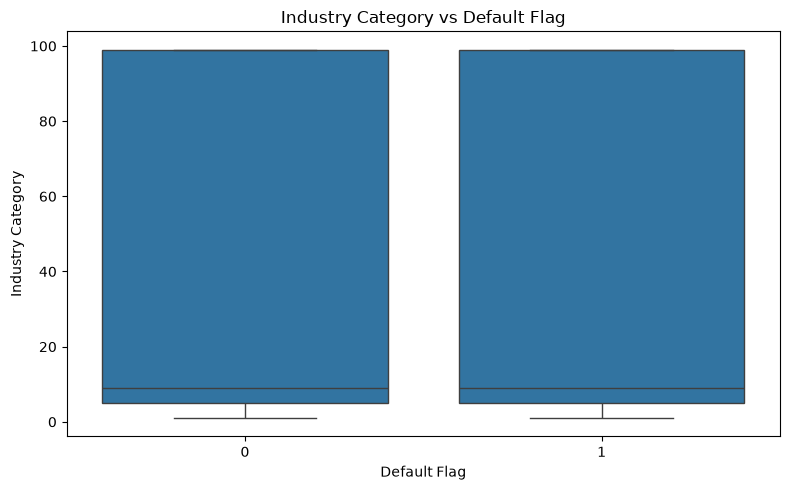

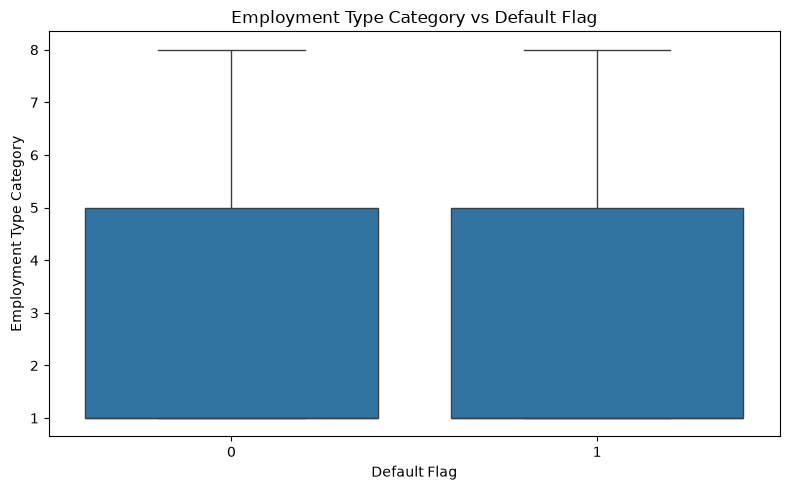

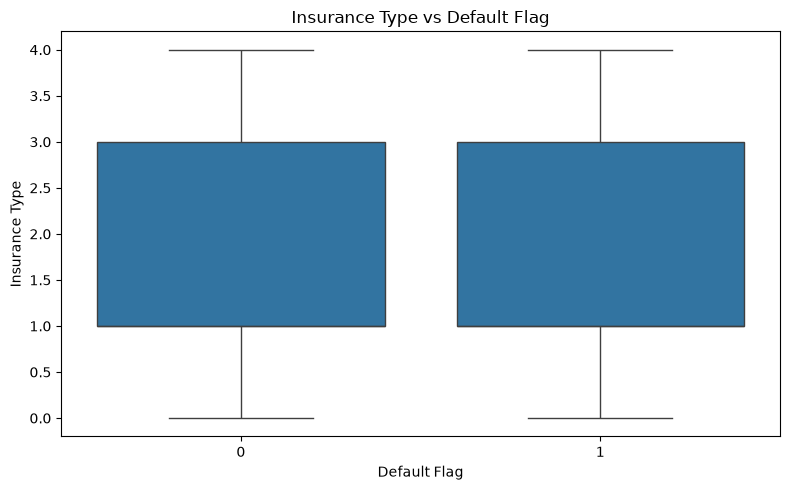

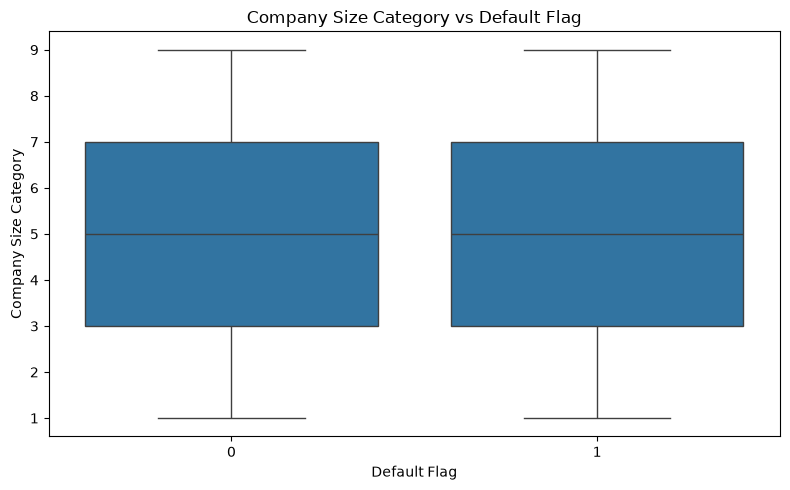

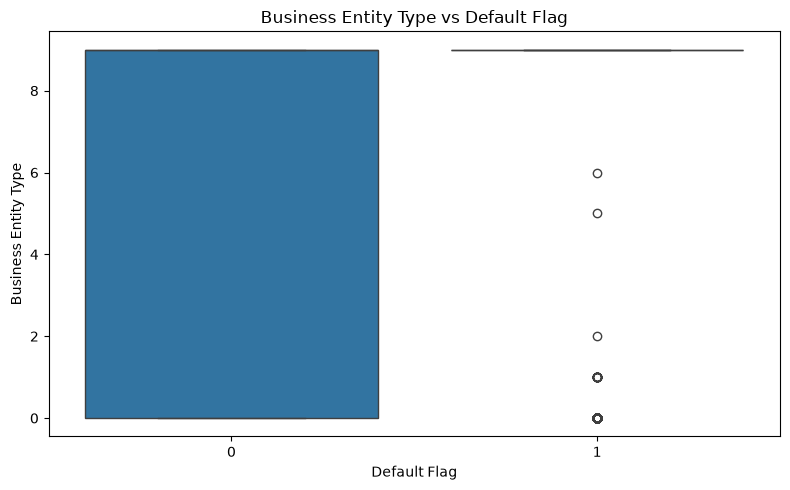

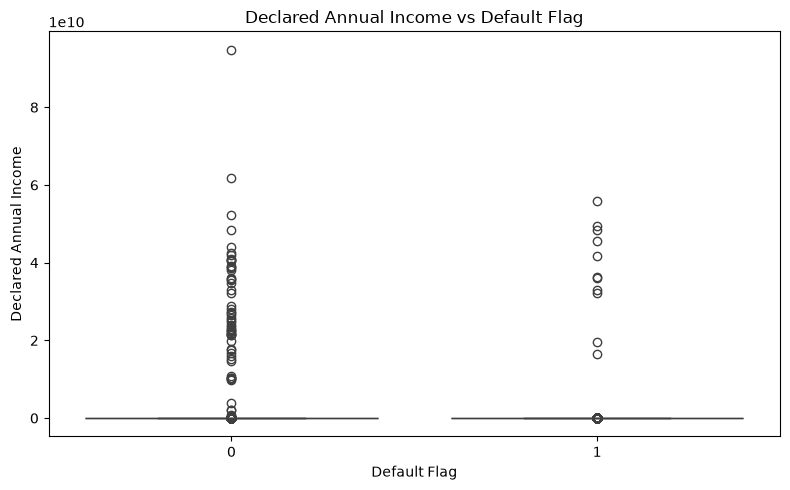

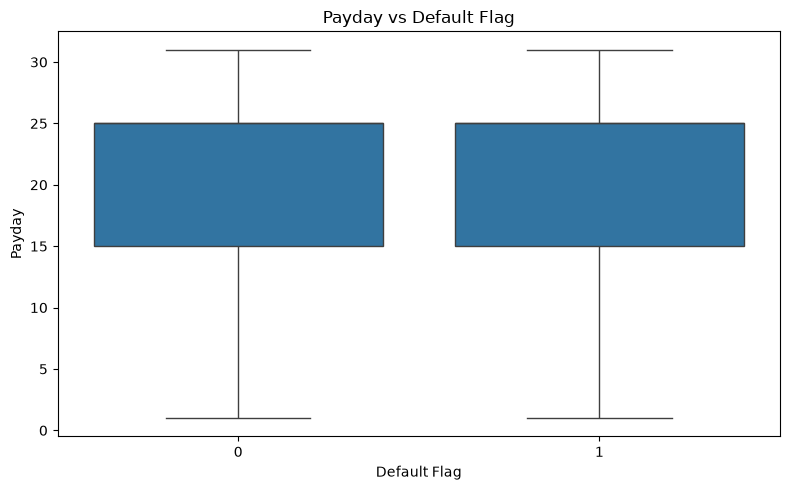

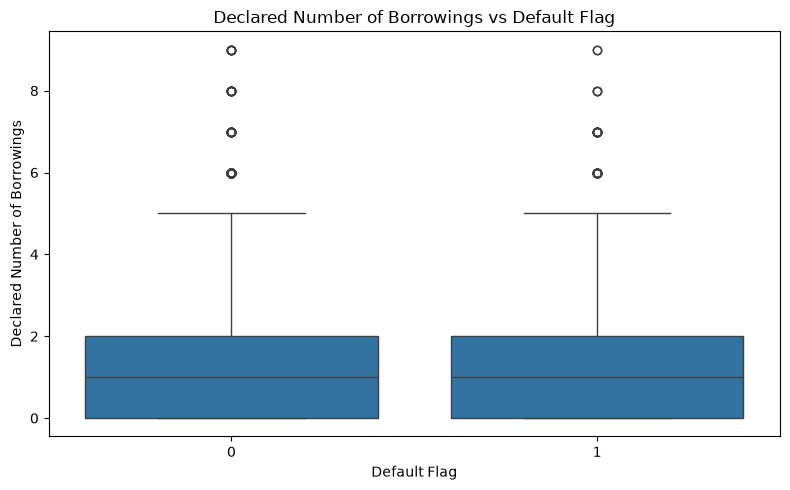

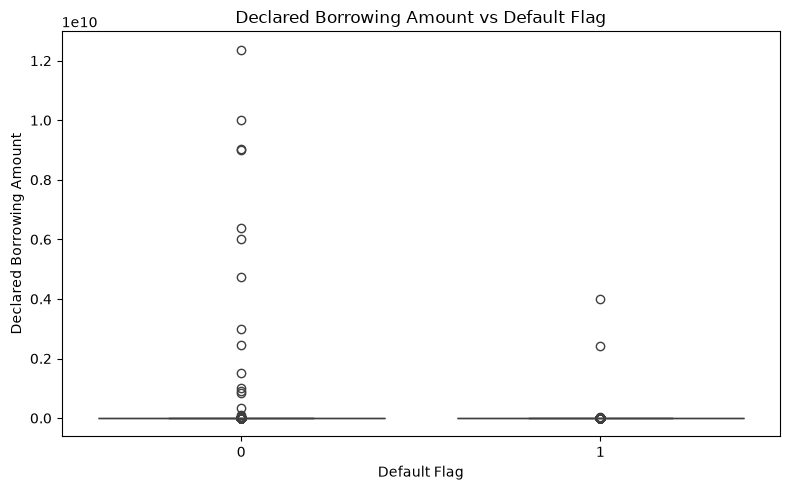

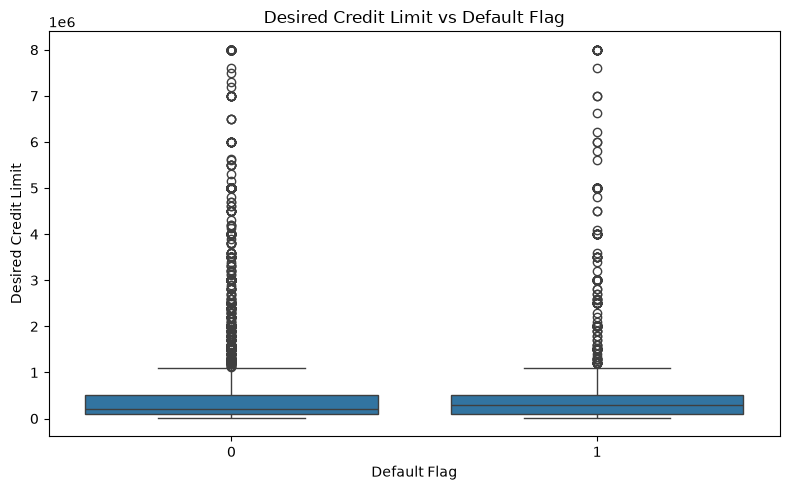

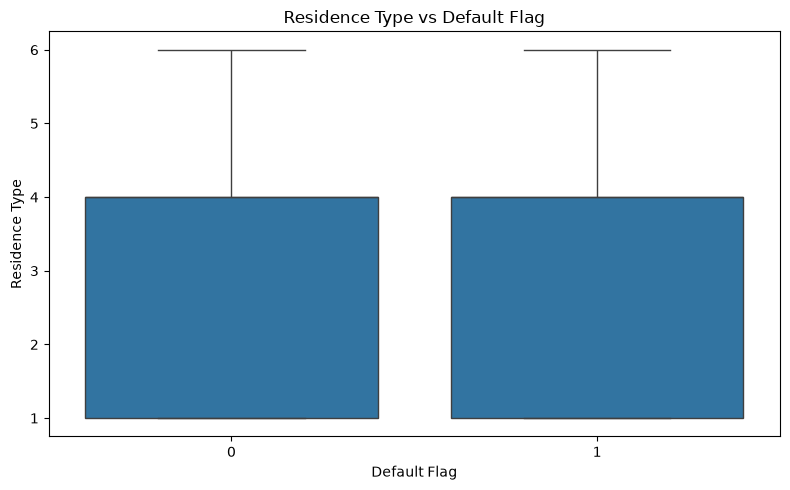

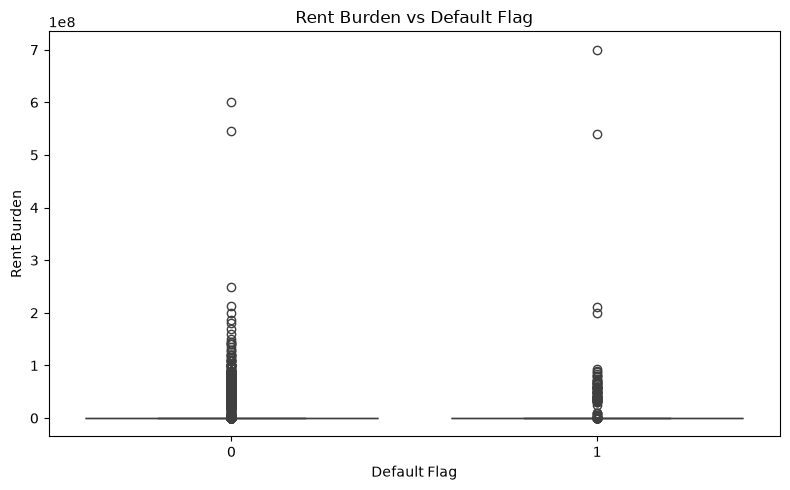

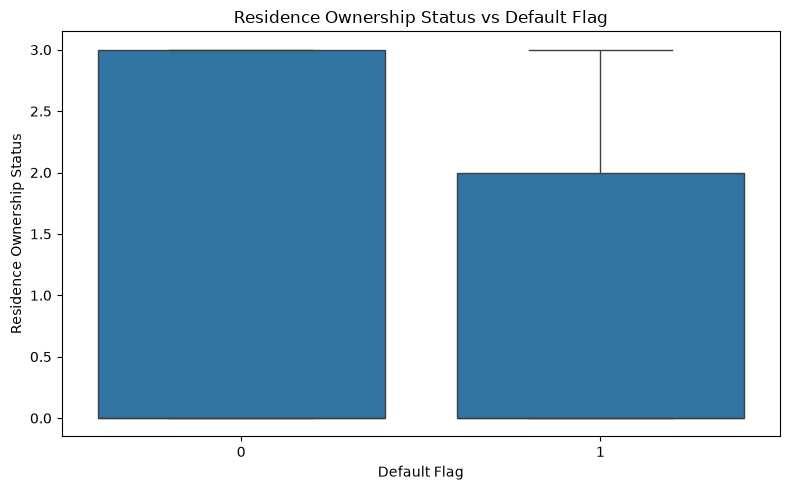

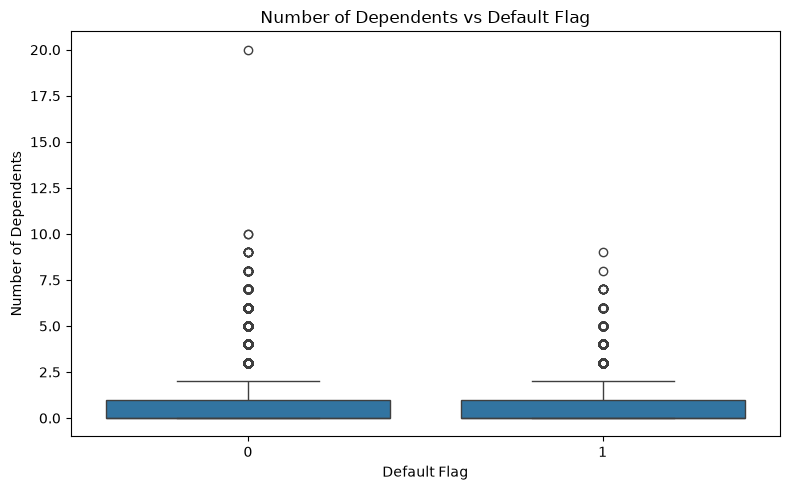

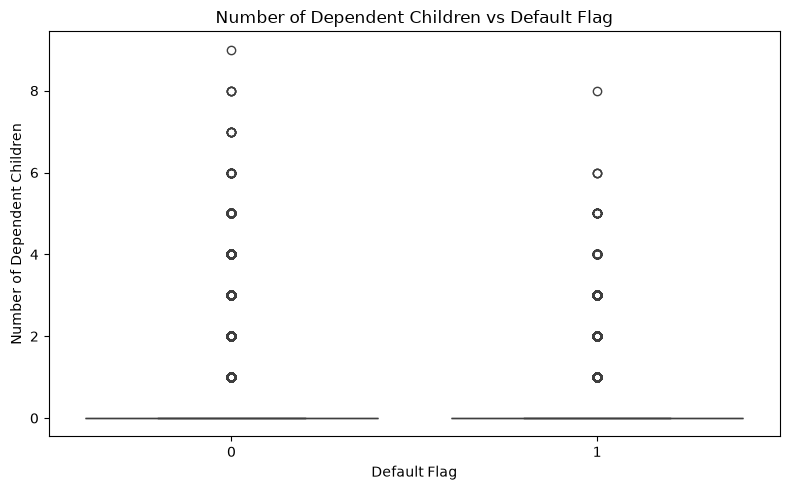

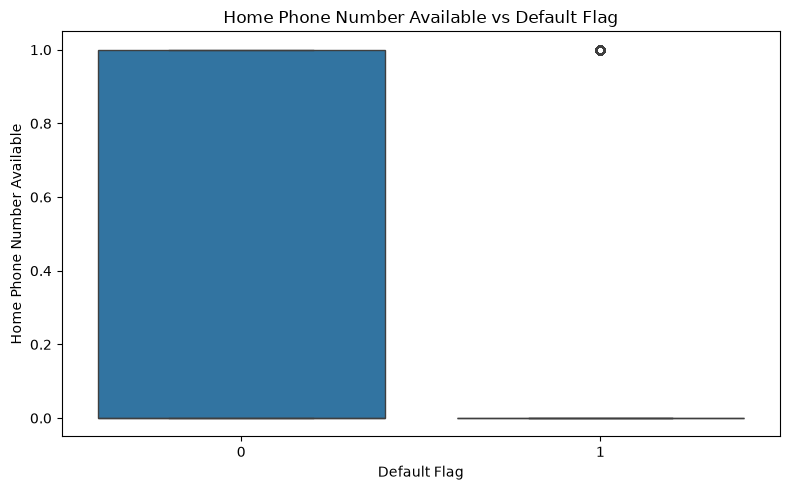

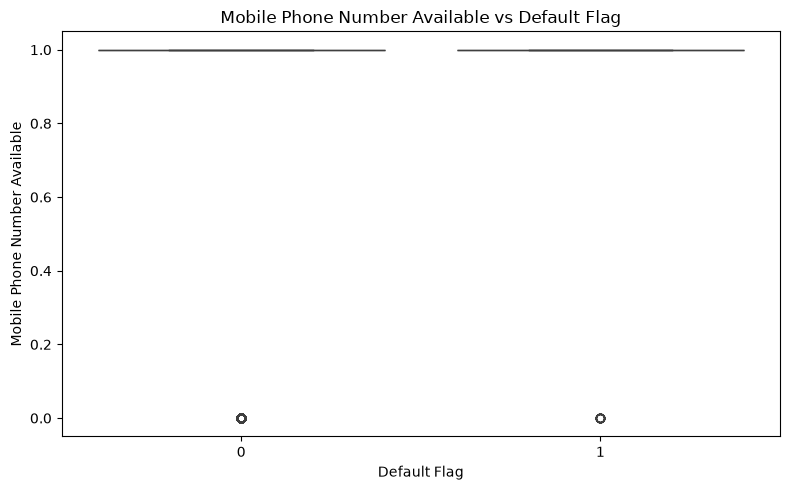

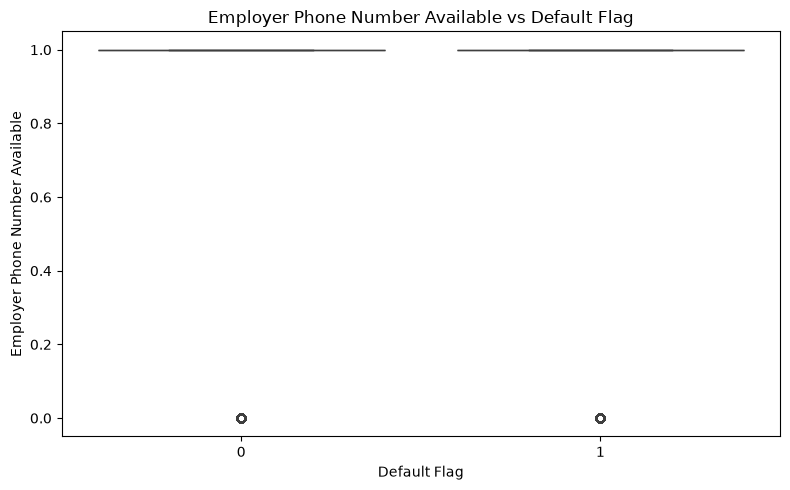

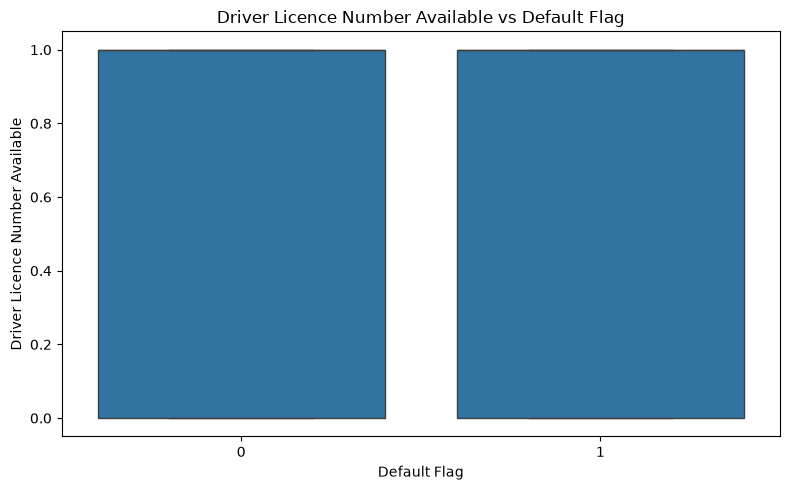

In [15]:
for col in numeric_cols:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=Factors_train_data,
        x=target,
        y=col
    )

    plt.title(f"{col} vs Default Flag")
    plt.xlabel("Default Flag")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

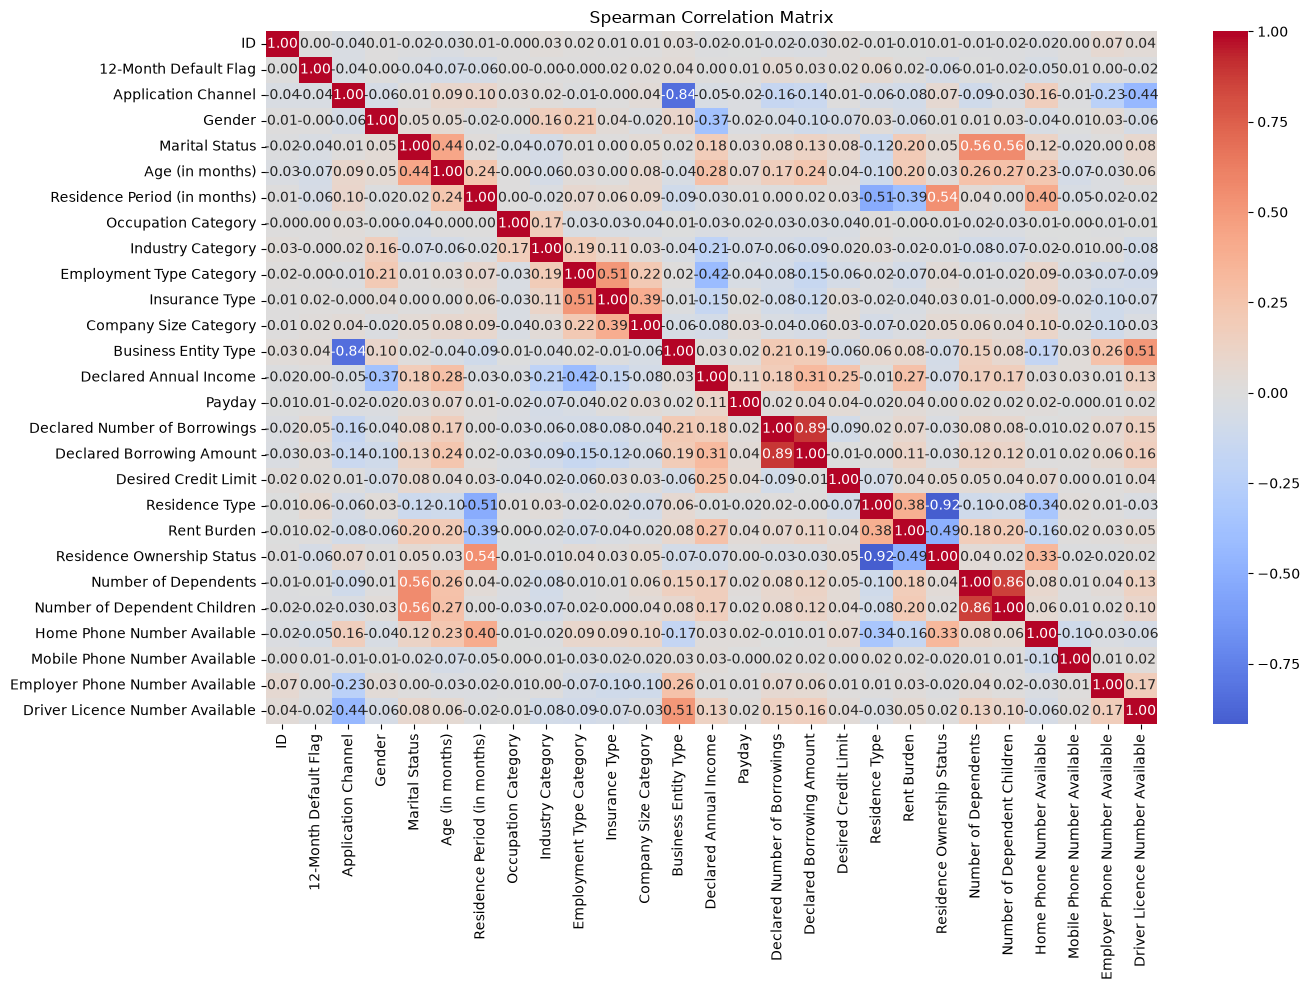

In [16]:
corr = Factors_train_data.select_dtypes(
    include='number'
).corr(method='spearman')

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)

plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

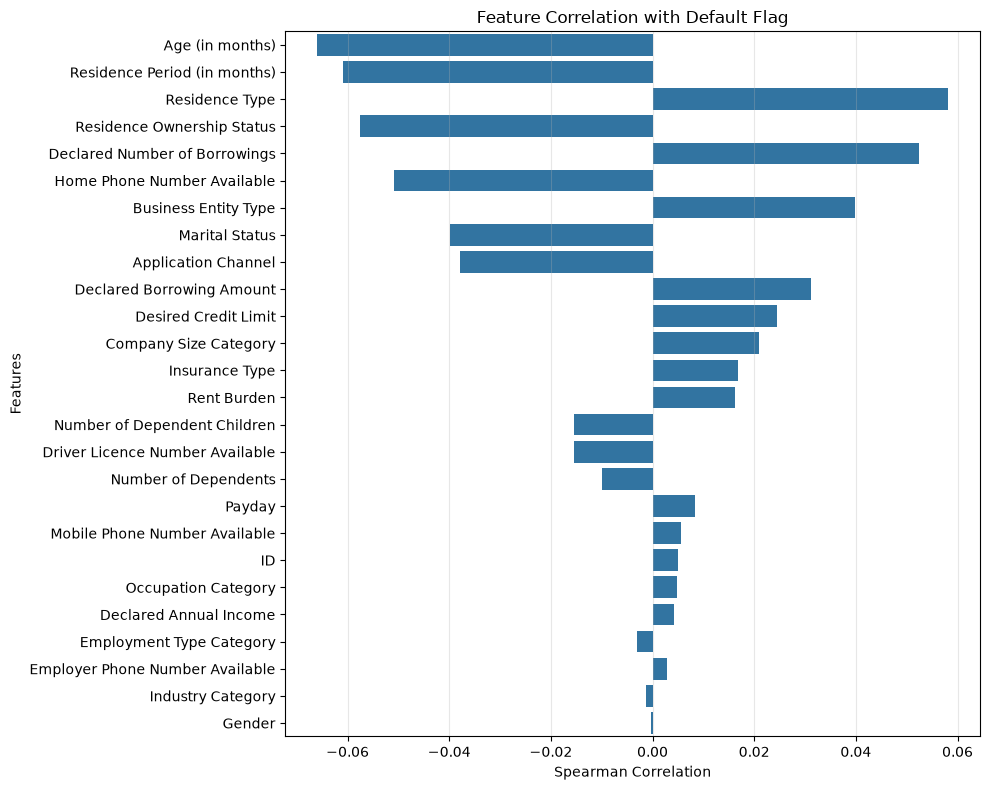

In [17]:
target_corr = (
    corr[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

plt.figure(figsize=(10, 8))

sns.barplot(
    x=target_corr.values,
    y=target_corr.index
)

plt.title("Feature Correlation with Default Flag")
plt.xlabel("Spearman Correlation")
plt.ylabel("Features")
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

##

##

## Modeling with Random Forest

In [29]:
feature_cols = [
    'Application Channel', 'Gender', 'Marital Status', 'Age (in months)',
    'Residence Period (in months)', 'Occupation Category', 'Industry Category',
    'Employment Type Category', 'Insurance Type', 'Company Size Category',
    'Business Entity Type', 'Declared Annual Income', 'Payday',
    'Declared Number of Borrowings', 'Declared Borrowing Amount',
    'Desired Credit Limit', 'Residence Type', 'Rent Burden',
    'Residence Ownership Status', 'Number of Dependents',
    'Number of Dependent Children', 'Home Phone Number Available',
    'Mobile Phone Number Available', 'Employer Phone Number Available',
    'Driver Licence Number Available'
]

factors_train = Factors_train_data[feature_cols]
factors_target = Factors_train_data[["12-Month Default Flag"]]

In [30]:
factors_train.head()

,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,Insurance Type,Company Size Category,Business Entity Type,Declared Annual Income,Payday,Declared Number of Borrowings,Declared Borrowing Amount,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,18,1,2,699,141,140,8,6,4,8,9,4800000,10,3,1400000,300000,1,50000,1,2,1,1,1,1,1
1,20,2,2,419,26,640,1,1,3,3,0,3500000,25,4,600000,200000,3,0,0,1,0,0,1,0,0
2,1,2,1,322,181,540,8,5,1,6,9,1560000,15,1,180000,100000,1,0,3,0,0,0,1,1,1
3,17,1,1,328,328,640,1,5,3,5,9,1800000,12,2,500000,100000,1,0,3,0,0,1,1,1,1
4,18,1,1,451,44,1040,16,1,1,5,9,5000000,21,1,1000000,100000,4,60000,0,0,0,0,1,1,1


In [31]:
factors_target.head()

,12-Month Default Flag
0,0
1,0
2,0
3,0
4,1


In [32]:
factors_train = np.array(factors_train)
factors_target = factors_target.values.ravel() # Flatten the target array to 1D

In [33]:
## Normalization and Train-Test Split
scaler_x = StandardScaler()
factors_train_scaled = scaler_x.fit_transform(factors_train)
factors_train_scaled

array([[ 0.22066724, -0.67391089,  1.48730964, ...,  0.0613467 ,
         0.18278051,  0.68629974],
       [ 0.65260009,  1.48387572,  1.48730964, ...,  0.0613467 ,
        -5.47104291, -1.45708928],
       [-3.45076197,  1.48387572, -0.67235495, ...,  0.0613467 ,
         0.18278051,  0.68629974],
       ...,
       [ 0.22066724, -0.67391089,  1.48730964, ...,  0.0613467 ,
         0.18278051,  0.68629974],
       [ 0.65260009, -0.67391089, -0.67235495, ...,  0.0613467 ,
        -5.47104291, -1.45708928],
       [ 0.65260009, -0.67391089, -0.67235495, ...,  0.0613467 ,
         0.18278051, -1.45708928]], shape=(68546, 25))

In [34]:
X_train_rf, y_train_rf = factors_train_scaled, factors_target
X_train_rf.shape, y_train_rf.shape

((68546, 25), (68546,))

In [35]:
## Train-Test split
x_train_split, x_test_split, y_train_split, y_test_split = train_test_split(
    factors_train_scaled, y_train_rf, test_size=0.2, random_state=42
)
x_train_split.shape, x_test_split.shape, y_train_split.shape, y_test_split.shape

((54836, 25), (13710, 25), (54836,), (13710,))

In [36]:
## Model Training - Random Forest Classifier
clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
clf.fit(x_train_split, y_train_split)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [37]:
def evaluate_model(y_true, y_pred, y_prob=None):

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
    }
    if y_prob is not None:
        metrics["ROC-AUC"] = roc_auc_score(y_true, y_prob)

    display(pd.DataFrame(
        metrics.items(),
        columns=["Metric", "Score"]
    ))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    print(classification_report(
        y_true,
        y_pred,
        zero_division=0
    ))

    return metrics

Metric,Score
Accuracy,0.904887
Precision,0.000000
Recall,0.000000
F1-score,0.000000
ROC-AUC,0.603258


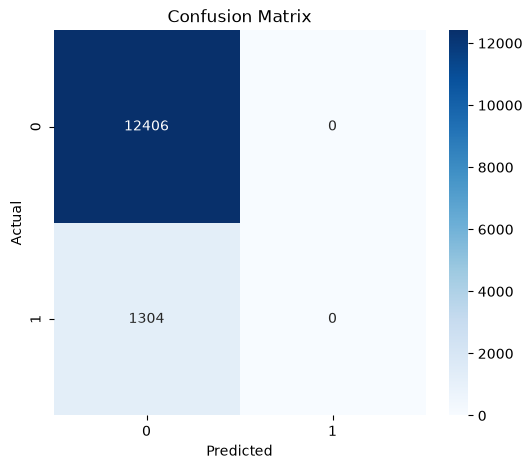

              precision    recall  f1-score   support

           0       0.90      1.00      0.95     12406
           1       0.00      0.00      0.00      1304

    accuracy                           0.90     13710
   macro avg       0.45      0.50      0.48     13710
weighted avg       0.82      0.90      0.86     13710



{'Accuracy': 0.9048869438366156, 'Precision': 0.0, 'Recall': 0.0, 'F1-score': 0.0, 'ROC-AUC': 0.6032576014574387}

In [38]:
evaluate_model(y_test_split, clf.predict(x_test_split), y_prob=clf.predict_proba(x_test_split)[:, 1])

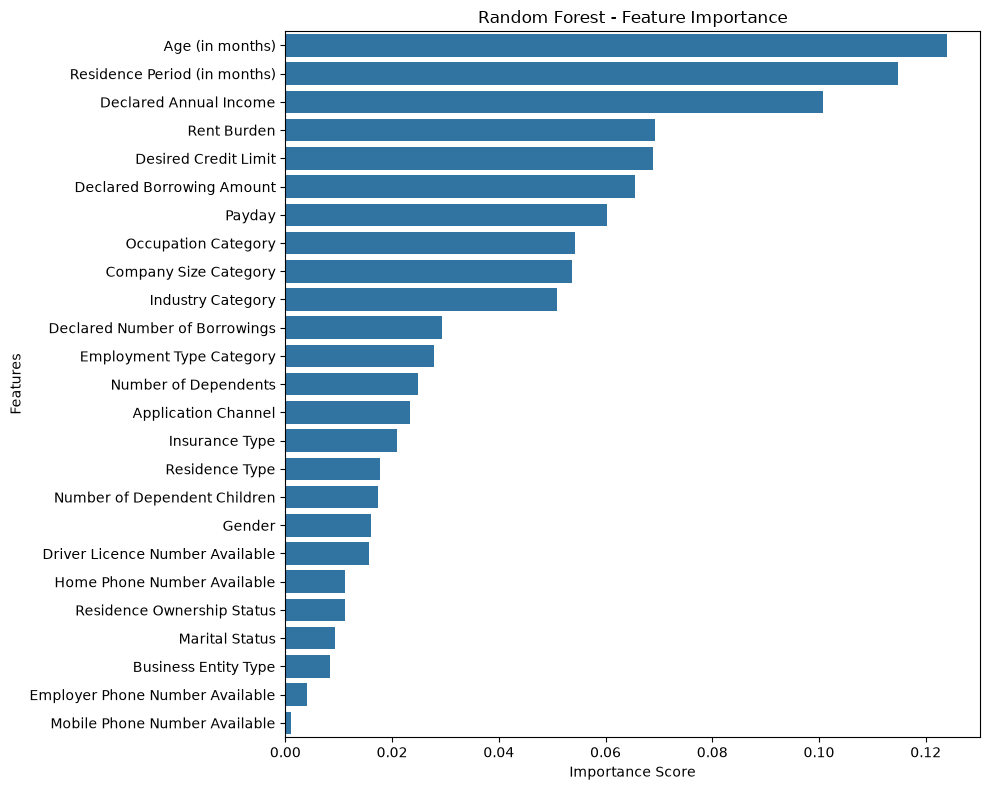

In [39]:
# Feature Importance Analysis
feature_importances = pd.Series(clf.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x=feature_importances.values, y=feature_importances.index)
plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

### Optional: Random Forest with Balanced Class Weights
Because default flag is highly imbalanced (~9.7% default), `class_weight='balanced'` gives equal penalty to minority class errors.

Metric,Score
Accuracy,0.903866
Precision,0.340909
Recall,0.011503
F1-score,0.022255
ROC-AUC,0.622067


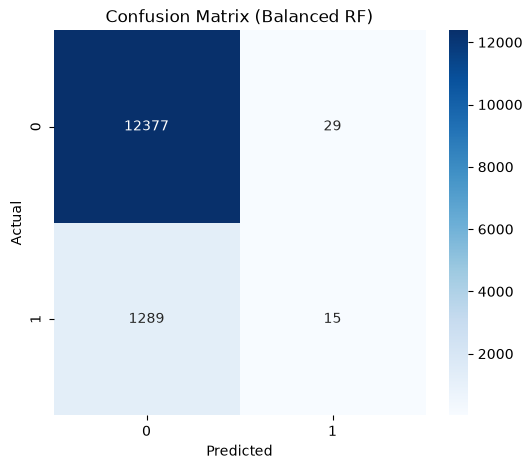

              precision    recall  f1-score   support

           0       0.91      1.00      0.95     12406
           1       0.34      0.01      0.02      1304

    accuracy                           0.90     13710
   macro avg       0.62      0.50      0.49     13710
weighted avg       0.85      0.90      0.86     13710



{'Accuracy': 0.9038657913931437, 'Precision': 0.3409090909090909, 'Recall': 0.011503067484662576, 'F1-score': 0.02225519287833828, 'ROC-AUC': 0.6220668383297613}

In [41]:
clf_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
clf_balanced.fit(x_train_split, y_train_split)
evaluate_model(y_test_split, clf_balanced.predict(x_test_split), y_prob=clf_balanced.predict_proba(x_test_split)[:, 1])

## Test set Prediction & Submission

In [42]:
factors_test = test_data[feature_cols]
factors_test.head()

,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,Insurance Type,Company Size Category,Business Entity Type,Declared Annual Income,Payday,Declared Number of Borrowings,Declared Borrowing Amount,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,20,1,1,301,301,640,1,1,1,3,0,3000000,10,0,0,200000,1,0,1,0,0,1,1,1,0
1,20,1,2,274,15,640,5,1,1,5,0,2700000,10,0,0,200000,1,40000,1,1,1,0,1,1,0
2,20,1,2,771,28,640,99,4,1,5,0,1500000,25,0,0,500000,4,50000,0,0,0,0,1,1,1
3,17,1,2,370,26,640,5,1,1,5,9,4200000,15,2,1000000,200000,4,54000,0,1,1,0,1,1,1
4,17,2,1,270,1,540,1,5,1,4,9,1400000,31,2,400000,150000,4,48000,0,0,0,0,1,1,0


In [43]:
factors_test_scaled = scaler_x.transform(factors_test)
factors_test_scaled.shape

(137091, 25)

In [44]:
clf.predict(factors_test_scaled)

array([0, 0, 0, ..., 0, 0, 0], shape=(137091,))

In [45]:
# 1. Predict
y_pred = clf.predict(factors_test_scaled)

# 2. Create submission with ID from test set
submission = pd.DataFrame({
    'ID': test_data['ID'].values,
    '12-Month Default Flag': y_pred
})

# 3. Export CSV
submission.to_csv(
    'submission_random_forest.csv',
    index=False
)

# 4. Check result
display(submission.head())

print("Shape:", submission.shape)
print("Missing values:\n", submission.isnull().sum())

,ID,12-Month Default Flag
0,211850001,0
1,211850002,0
2,211850003,0
3,211870001,0
4,211880001,0


Shape: (137091, 2)
Missing values:
ID                       0
12-Month Default Flag    0
dtype: int64


In [46]:
submission[["12-Month Default Flag"]].value_counts()

12-Month Default Flag
0    137081
1        10
Name: count, dtype: int64

In [47]:
# Alternative: Export submission from Balanced Random Forest
y_pred_bal = clf_balanced.predict(factors_test_scaled)

submission_balanced = pd.DataFrame({
    'ID': test_data['ID'].values,
    '12-Month Default Flag': y_pred_bal
})
submission_balanced.to_csv('submission_random_forest_balanced.csv', index=False)
display(submission_balanced["12-Month Default Flag"].value_counts())

12-Month Default Flag
0    136541
1       550
Name: count, dtype: int64